# Iceberg and ship classification

Two radar polarizations describe the same observation. This experiment learns image features
from those bands and tests whether incidence-angle metadata adds useful information.

The historical single-model public leaderboard scores were **0.19348** and **0.20507**.
The experiment below uses the original fixed local holdout; leaderboard scoring is a separate evaluation.

**Requirements:** the project environment and authorized Kaggle data. Set `ICEBERG_DATA_DIR`.
The default profile is the complete modern baseline. To inspect an existing completed experiment,
set `ICEBERG_EXISTING_RUN` to its run directory; its input and artifact fingerprints are verified.

Set `ICEBERG_CV_RUN` to a completed grouped CV directory to inspect the stability analysis.

## 1. Experiment configuration

The image-only baseline uses all training records outside the fixed holdout. The metadata profile
changes the input branch while keeping the split and training budget fixed. Choose the profile
before comparing results; a reduced budget answers a different experimental question.

In [1]:
import csv
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.model_selection import StratifiedShuffleSplit

from iceberg.data import load_data, sha256
from iceberg.runtime import evaluate, predict, train, verify_run

PROJECT = Path.cwd()
if not (PROJECT / "pyproject.toml").exists():
    PROJECT = PROJECT.parent
DATA_DIR = Path(os.environ.get("ICEBERG_DATA_DIR", PROJECT / ".local/data"))
PROFILE = os.environ.get("ICEBERG_PROFILE", "baseline")
CONFIG = json.loads((PROJECT / "configs" / f"{PROFILE}.json").read_text())
REUSE = os.environ.get("ICEBERG_EXISTING_RUN")
RUN_ROOT = Path(os.environ.get("ICEBERG_RUN_DIR", PROJECT / ".local/runs"))
RUN_DIR = (
    Path(REUSE).resolve() if REUSE else RUN_ROOT / datetime.now(UTC).strftime("%Y%m%dT%H%M%S%f")
)
assert (DATA_DIR / "train.json").is_file(), "Download data and set ICEBERG_DATA_DIR first"
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(json.dumps(CONFIG, indent=2))

{
  "name": "modern-image-and-angle",
  "seed": 1017,
  "split_seed": 25,
  "validation_fraction": 0.159,
  "filters": 16,
  "hidden": 64,
  "use_angle": true,
  "dropout": 0.3,
  "batch_size": 64,
  "epochs": 30,
  "learning_rate": 0.001,
  "min_learning_rate": 1e-05,
  "weight_decay": 0.0001,
  "gradient_clip": 1.0,
  "augment": true,
  "max_train_rows": null,
  "threads": 4,
  "device": "auto",
  "deterministic": false,
  "mixed_precision": true,
  "tta": "flips"
}


## 2. Radar bands and incidence angle

The two 75×75 bands contain radar backscatter in dB, rather than ordinary RGB pixel values.
Keeping both channels aligned preserves their correspondence. A training-fitted channel
standardizer retains relative brightness differences between observations.

Missing incidence angles remain missing until preprocessing. The optional metadata branch
uses training-median imputation plus a missingness indicator, avoiding a fictitious physical angle.

{'records': 1604, 'radar_shape': (1604, 2, 75, 75), 'iceberg_fraction': 0.469451367855072, 'missing_angles': 133}


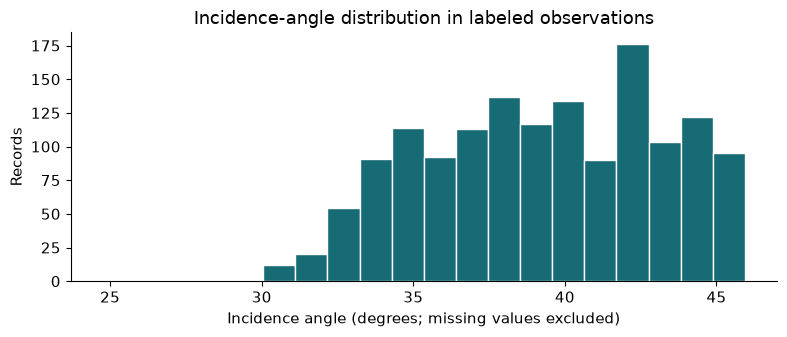

In [2]:
data = load_data(DATA_DIR / "train.json", labeled=True)
angles = data.angles.reshape(-1)
observed = np.isfinite(angles)
print(
    {
        "records": len(data.ids),
        "radar_shape": data.images.shape,
        "iceberg_fraction": float(data.targets.mean()),
        "missing_angles": int((~observed).sum()),
    }
)
fig, ax = plt.subplots()
ax.hist(angles[observed], bins=20, color="#176b75", edgecolor="white")
ax.set(
    title="Incidence-angle distribution in labeled observations",
    xlabel="Incidence angle (degrees; missing values excluded)",
    ylabel="Records",
)
fig.tight_layout()
plt.show()

The histogram describes coverage, not predictive value. Incidence angle can encode acquisition
structure, so a random stratified split alone does not establish performance on new acquisitions.
An angle-grouped evaluation is a separate robustness check; angle lookup against labels is not part of this model.

## 3. Validation split

Retain the original seed-25 stratified holdout of 256 records. Fit every preprocessing statistic
on the remaining training rows. The holdout is used for checkpoint selection, so it is not a
second untouched test set.

In [3]:
split = StratifiedShuffleSplit(
    n_splits=1, test_size=CONFIG["validation_fraction"], random_state=CONFIG["split_seed"]
)
train_indices, valid_indices = next(split.split(data.images, data.targets))
assert not set(train_indices) & set(valid_indices)
print(
    {
        "training_rows": len(train_indices),
        "holdout_rows": len(valid_indices),
        "training_iceberg_fraction": float(data.targets[train_indices].mean()),
        "holdout_iceberg_fraction": float(data.targets[valid_indices].mean()),
    }
)

{'training_rows': 1348, 'holdout_rows': 256, 'training_iceberg_fraction': 0.469584584236145, 'holdout_iceberg_fraction': 0.46875}


## 4. Convolutional model

```text
Two radar bands → training-fitted scaling → four CNN stages → average + max pooling ─┐
                                                                                   ├→ dense head → probability
Incidence angle → training-fitted imputation/scaling + missing flag → optional branch ┘
```

Progressive downsampling reduces the cost of repeated full-resolution convolutions. Native
BatchNorm2d normalizes convolutional activations; LayerNorm avoids dependence on the last
minibatch in the dense head. Standard AdamW and a cosine schedule train over ordinary epochs.

Spatial flips, right-angle rotations and mild affine transforms are shared across the two bands.
Extreme zoom and RGB color augmentation would change the physical input assumptions and are omitted.

## 5. Development run and checkpoint selection

This separate single-holdout development run selects the checkpoint with the lowest held-out log loss.
The primary grouped CV below instead retains fixed final-epoch checkpoints. The run directory retains the resolved recipe,
preprocessing parameters, actual split, training history, source/input identities and checksums.
An existing run is reused only after verification.

**Held-out log loss: 0.2012.** Training used 1348 records; evaluation used 256 holdout records. This is a local validation metric.

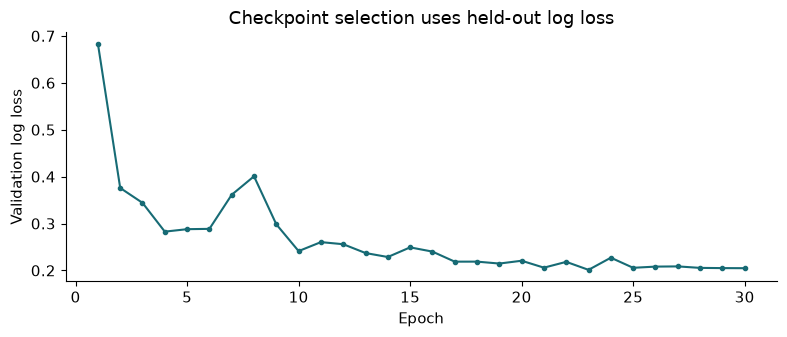

In [4]:
if REUSE:
    manifest = verify_run(RUN_DIR, DATA_DIR / "train.json")
    assert manifest["config"] == CONFIG, "Select the profile that produced this run"
else:
    manifest = train(DATA_DIR / "train.json", RUN_DIR, CONFIG)
metrics = json.loads((RUN_DIR / "metrics.json").read_text())
display(
    Markdown(
        f"**Held-out log loss: {metrics['validation_log_loss']:.4f}.** "
        f"Training used {manifest['train_rows']} records; evaluation used "
        f"{manifest['validation_rows']} holdout records. This is a local validation metric."
    )
)
history = json.loads((RUN_DIR / "history.json").read_text())
fig, ax = plt.subplots()
ax.plot(
    [r["epoch"] for r in history],
    [r["validation_log_loss"] for r in history],
    color="#176b75",
    marker="o",
    markersize=3,
)
ax.set(
    title="Checkpoint selection uses held-out log loss",
    xlabel="Epoch",
    ylabel="Validation log loss",
)
fig.tight_layout()
plt.show()

## 6. Holdout predictions

Reload the saved checkpoint and preprocessing before inspecting its errors. Distributional
separation is useful context but does not replace log loss or establish probability calibration.
Use the same inference and test-time augmentation settings for validation and submission.

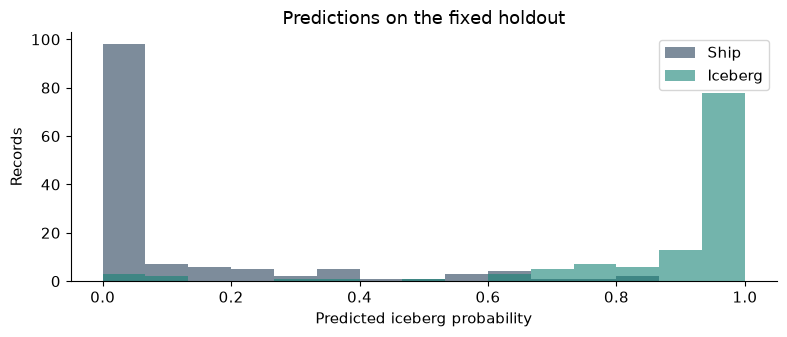

In [5]:
reloaded = evaluate(RUN_DIR / "model.pt", DATA_DIR / "train.json")
assert abs(reloaded["validation_log_loss"] - metrics["validation_log_loss"]) < 1e-5
with (RUN_DIR / "validation.csv").open() as stream:
    rows = list(csv.DictReader(stream))
fig, ax = plt.subplots()
for target, label, color in [(0, "Ship", "#263f59"), (1, "Iceberg", "#168376")]:
    values = [float(r["probability"]) for r in rows if int(r["target"]) == target]
    ax.hist(values, bins=np.linspace(0, 1, 16), alpha=0.6, label=label, color=color)
ax.set(
    title="Predictions on the fixed holdout",
    xlabel="Predicted iceberg probability",
    ylabel="Records",
)
ax.legend()
fig.tight_layout()
plt.show()

The overlap identifies uncertainty and confident mistakes. Compare image-only and metadata
experiments with the same split, seed and inference recipe. Improvements on this small holdout
need confirmation on the competition evaluation and an acquisition-grouped split.

## 7. Grouped cross-validation and training-seed sensitivity

The primary stability check uses five class-stratified folds grouped by observed incidence angle,
and two fixed training seeds on identical assignments. Each model retains its final checkpoint
after 30 fixed epochs, so outer-fold labels do not choose the epoch. Preprocessing is fitted
inside each fold.

All 133 missing-angle records in the labeled data are ships, while test observations have no
missing angles. Inspect known-angle OOF loss separately from the overall metric. Exact angles
are acquisition proxies, not verified scene IDs; unknown angles receive individual group IDs.

The analyzer verifies input, split, child-checkpoint and OOF fingerprints before reconstructing
metrics. Fold spread and training-seed spread describe different sources of variation; neither
is a confidence interval. Every fold and seed is retained.

**Known-angle grouped OOF log loss: 0.2206.** All-row OOF log loss: 0.2048. All-row training-seed pooled-loss range: 0.0045.

{'records_per_seed': 1604, 'seeds': [1017, 2027], 'maximum_shared_angles': 0, 'missing_angle_positives': 0}


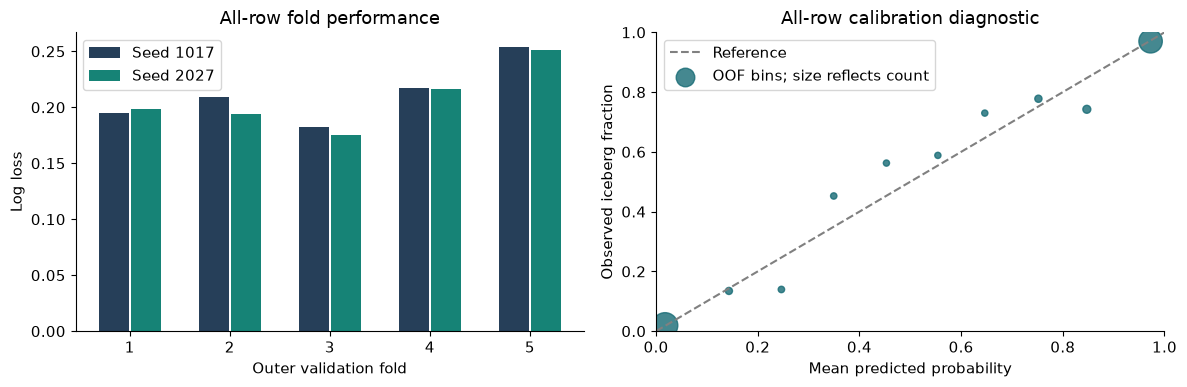

In [6]:
from iceberg.cv import analyze_cv

CV_LOCATION = os.environ.get("ICEBERG_CV_RUN")
CV_DIR = Path(CV_LOCATION).resolve() if CV_LOCATION else None
if CV_DIR:
    cv_report = analyze_cv(CV_DIR, DATA_DIR / "train.json")
    display(
        Markdown(
            f"**Known-angle grouped OOF log loss: {cv_report['strata']['known_angle']['log_loss']:.4f}.** "
            f"All-row OOF log loss: {cv_report['pooled_oof']['log_loss']:.4f}. "
            f"All-row training-seed pooled-loss range: {cv_report['seed_distribution']['log_loss']['range']:.4f}."
        )
    )
    print(
        {
            "records_per_seed": cv_report["rows"],
            "seeds": [r["seed"] for r in cv_report["seed_results"]],
            "maximum_shared_angles": max(
                r["shared_known_angles"] for r in cv_report["split_audit"]
            ),
            "missing_angle_positives": cv_report["strata"]["missing_angle"]["positives"],
        }
    )
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for number, record in enumerate(cv_report["seed_results"]):
        x = np.arange(len(record["fold_metrics"]))
        offset = (number - (len(cv_report["seed_results"]) - 1) / 2) * 0.32
        axes[0].bar(
            x + offset,
            [r["log_loss"] for r in record["fold_metrics"]],
            width=0.3,
            label=f"Seed {record['seed']}",
            color=["#263f59", "#168376"][number % 2],
        )
    axes[0].set(
        xticks=x,
        xticklabels=x + 1,
        xlabel="Outer validation fold",
        ylabel="Log loss",
        title="All-row fold performance",
    )
    axes[0].legend()
    bins = [b for b in cv_report["calibration_bins"] if b["rows"]]
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Reference")
    axes[1].scatter(
        [b["mean_probability"] for b in bins],
        [b["observed_positive_fraction"] for b in bins],
        s=[max(20, b["rows"] / 2) for b in bins],
        color="#176b75",
        alpha=0.8,
        label="OOF bins; size reflects count",
    )
    axes[1].set(
        xlim=(0, 1),
        ylim=(0, 1),
        xlabel="Mean predicted probability",
        ylabel="Observed iceberg fraction",
        title="All-row calibration diagnostic",
    )
    axes[1].legend()
    fig.tight_layout()
    plt.show()
else:
    print("Set ICEBERG_CV_RUN to inspect completed, verified cross-validation artifacts.")

Calibration bins are diagnostics, not a fitted correction. Sparse bins need their record counts.
The paired-seed OOF ensemble averages only models that held out a record. New test predictions
use all retained fold/seed models, each with its own training-fitted preprocessing.

## 8. Test predictions

Set `ICEBERG_FULL_TEST=1` for all 8,424 authorized test records. Prediction retains their IDs and
order, and writes a receipt binding the output to its input and checkpoint. Producing a CSV and
submitting it for a leaderboard score are distinct operations.

In [7]:
if os.environ.get("ICEBERG_FULL_TEST", "0") == "1":
    if CV_DIR:
        from iceberg.cv import predict_cv

        output = CV_DIR / "submission.csv"
        receipt_path = output.with_suffix(".receipt.json")
        if output.exists() and receipt_path.exists():
            receipt = json.loads(receipt_path.read_text())
            parent = json.loads((CV_DIR / "cv-manifest.json").read_text())
            assert receipt["cv_manifest_sha256"] == sha256(CV_DIR / "cv-manifest.json")
            assert receipt["input_sha256"] == sha256(DATA_DIR / "test.json")
            assert receipt["output_sha256"] == sha256(output)
            assert [r["sha256"] for r in receipt["checkpoints"]] == [
                r["checkpoint_sha256"] for r in parent["fold_runs"]
            ]
            print("Verified retained full-test predictions and their producer receipt.")
        else:
            receipt = predict_cv(CV_DIR, DATA_DIR / "test.json", output)
        print(
            {
                "rows": receipt["rows"],
                "models": receipt["model_count"],
                "aggregation": receipt["aggregation"],
                "output_sha256": receipt["output_sha256"],
            }
        )
    else:
        receipt = predict(RUN_DIR / "model.pt", DATA_DIR / "test.json", RUN_DIR / "submission.csv")
        print(receipt)
else:
    print("Full-test inference disabled; set ICEBERG_FULL_TEST=1 to enable it.")

Verified retained full-test predictions and their producer receipt.
{'rows': 8424, 'models': 10, 'aggregation': 'equal_weight_mean_probability_across_all_folds_and_seeds', 'output_sha256': '96943ffe32245774a6729f293ec0cc04a256bcc43ae2f4e37bbab3b8e0817c6b'}


## 9. Experiment artifacts

Local artifacts remain available without a tracking server. The optional MLflow import checks
completed-run fingerprints and logs them to an existing deployment. Docker Lab can expose an
existing SeaweedFS client mount read-only. Service deployment and storage administration remain external.

The Kaggle entry notebook runs the package from an attached code wheel and saves a portable
run bundle without requiring access to private tracking infrastructure.

[Results](../docs/results.md) · [Method changes](../docs/migration.md) ·
[Runbook](../docs/reproduction.md) · [Tracking](../docs/mlops.md)